Clasificación de dígitos

Nombre: Elisa Polet Gonzalez Castro
  
Profesor: Miguel Angel Evangelista Alvarado



Explicación
Primero se Carga la base de datos digits,que contiene imágenes de números escritos a mano.
Después revisé su contenido para conocer la información con la que voy a trabajár.

In [1]:
from sklearn.datasets import load_digits

digits = load_digits()


En este paso reviséla descripción de los datos para conocer mejor la información antes de comenzar a entrenar el modelo.

In [2]:
digits.keys()


dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [4]:
print(digits.DESCR)


.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

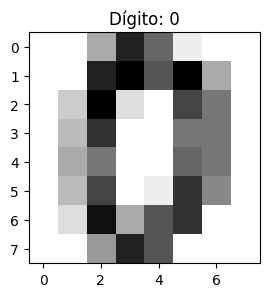

In [6]:
import matplotlib.pyplot as plt

# Definir las variables usando el primer elemento del dataset
image = digits.images[0]
label = digits.target[0]

plt.figure(figsize=(3, 3))
plt.imshow(image, cmap=plt.cm.gray_r)
plt.title(f'Dígito: {label}')
plt.show()

Seleccioné una imagen de la base de datos para ogservar cómo está formada y conocer qué número representa. Esto me ayuda a entender cómo la computadora recibe las imágenes.

In [7]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target,
    test_size=0.2, random_state=42
)

# One-hot encode the target variable
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)


Separé las imágenes en dos grupos.Uno sirve para que la computadora aprenda y el otro para comprobar si realmente puede reconocer los números sin haberlos utilizado durante el entrenamiento.

In [8]:
print(X_train.shape)
print(X_test.shape)


(1437, 64)
(360, 64)


Normalicé las imágenes para que sus valores fueran más uniformes.Esto fascilita el procesamiento de la información durante el aprendizaje de la red neuronal.

In [9]:
reshaped_tensor = tf.reshape(X_train[0], shape=(8, 8))
print(reshaped_tensor)


tf.Tensor(
[[ 0.  0.  3. 14.  1.  0.  0.  0.]
 [ 0.  0. 12. 12.  0.  0.  0.  0.]
 [ 0.  3. 16.  6.  0.  0.  0.  0.]
 [ 0.  5. 16.  2.  0.  0.  0.  0.]
 [ 0.  6. 16.  2.  5.  2.  0.  0.]
 [ 0.  4. 16.  2. 12. 15.  2.  0.]
 [ 0.  1. 14. 13.  2. 13. 11.  0.]
 [ 0.  0.  3. 11. 16. 13.  4.  0.]], shape=(8, 8), dtype=float64)


Se acomodan los datos para que la red neuronal los reconozca como imágenes de 8 por 8 píxeles y pueda procesarlos correctamente.

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

# Crear el modelo de CNN
model = Sequential([
    Conv2D(32, kernel_size=(3, 3),
        activation='relu',
        input_shape=(8, 8, 1)
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Construí una red neuronal convolucional con diferentes capas.Cada una tiene una función:analizar las imágenes,reducir la información,organizarla y finalmente clacificarlos números.

In [11]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)

In [13]:
# 1. Redimensionar los datos a (8, 8, 1) para que coincidan con la entrada de la CNN
X_train_reshaped = X_train.reshape(-1, 8, 8, 1)
X_test_reshaped = X_test.reshape(-1, 8, 8, 1)

# 2. Compilar el modelo antes de entrenarlo
model.compile(
    optimizer=adam_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Entrenar el modelo con los datos redimensionados
history = model.fit(
    X_train_reshaped, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.5570 - loss: 1.6289 - val_accuracy: 0.8507 - val_loss: 0.6307
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9356 - loss: 0.3196 - val_accuracy: 0.9201 - val_loss: 0.2601
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9678 - loss: 0.1502 - val_accuracy: 0.9375 - val_loss: 0.1889
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9748 - loss: 0.1017 - val_accuracy: 0.9444 - val_loss: 0.1462
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9861 - loss: 0.0681 - val_accuracy: 0.9583 - val_loss: 0.1205
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9878 - loss: 0.0565 - val_accuracy: 0.9618 - val_loss: 0.0985
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9930 - loss: 0.0378 - val_accuracy: 0.9722 - val_loss: 0.0933
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9956 - loss: 0.0313 - val_accuracy: 0.9722 - val_

Entrené la red neuronal durante 20 épocas para que pudiera aprender a reconocer los números.También reservé una parte de los datos para revisar cómo iba mejorando.

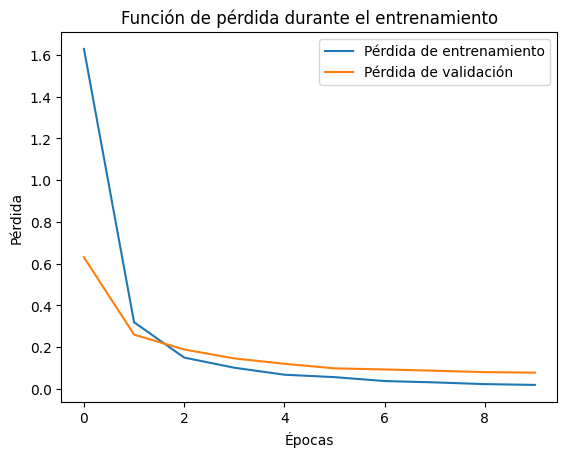

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


Se cbserva una grafica para el modelo estaba aprendiendo correctamente y si sus errores iban disminuyendo durante el entrenamiento.

In [16]:
loss, accuracy = model.evaluate(X_test_reshaped, y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9694 - loss: 0.0630
Loss: 0.06298405677080154, Accuracy: 0.9694444537162781


Despues de entrenar el modelo,utilicé las imágenes de prueba para comprobar qué tan bien reconoce los números y conocer su porcentaje de exactitud.

In [18]:
import numpy as np
from sklearn.metrics import confusion_matrix, recall_score

# Usar los datos de prueba redimensionados para la predicción
y_pred = model.predict(X_test_reshaped)
y_pred_classes = np.argmax(y_pred, axis=1)
# Convert y_test back to multiclass format
y_test_classes = np.argmax(y_test, axis=1)

conf_matrix = confusion_matrix(y_test_classes, y_pred_classes)
sensitivity = recall_score(y_test_classes, y_pred_classes, average=None)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


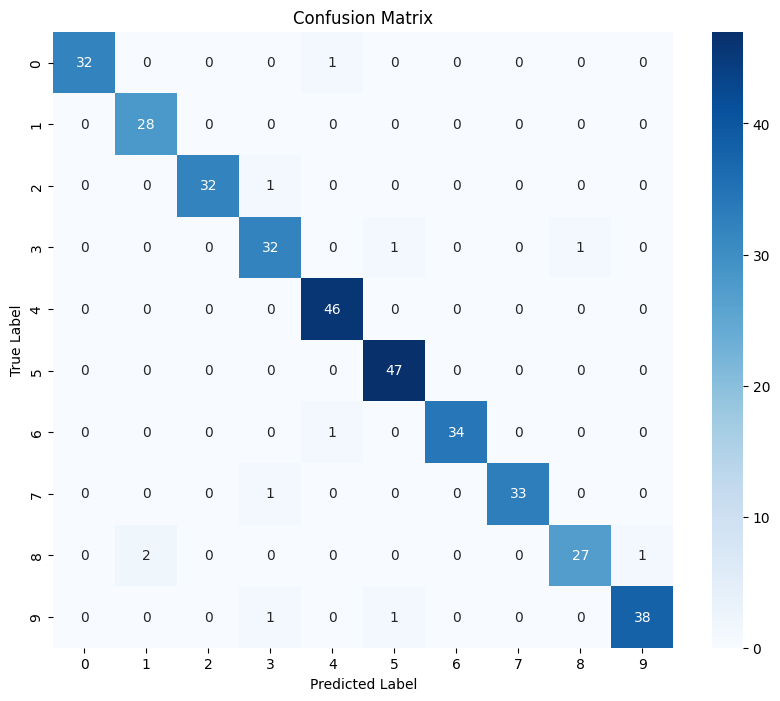

Sensitivity (Recall) for each class:
Class 0: 0.9696969696969697
Class 1: 1.0
Class 2: 0.9696969696969697
Class 3: 0.9411764705882353
Class 4: 1.0
Class 5: 1.0
Class 6: 0.9714285714285714
Class 7: 0.9705882352941176
Class 8: 0.9
Class 9: 0.95


In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualizar la matriz de confusión como una imagen de colores
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Mostrar la sensibilidad (recall) para cada clase
print('Sensitivity (Recall) for each class:')
for i in range(10):
    print(f'Class {i}: {sensitivity[i]}')

El archivo /content/mi_numero.png no fue encontrado.
Creando una imagen de prueba temporal (un número 5) para evitar fallos en el flujo...


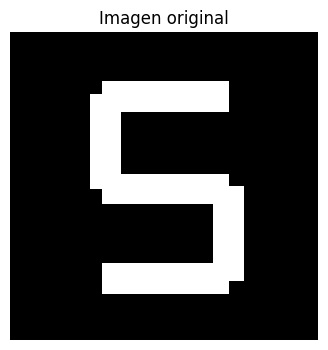

In [22]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import os

ruta = "/content/mi_numero.png"

# Verificar si la imagen existe en el entorno
if not os.path.exists(ruta):
    print(f"El archivo {ruta} no fue encontrado.")
    print("Creando una imagen de prueba temporal (un número 5) para evitar fallos en el flujo...")
    # Crear una imagen negra de 100x100 con un número 5 blanco
    img_temp = Image.new('L', (100, 100), color=0)
    draw = ImageDraw.Draw(img_temp)
    # Dibujar algo similar a un número
    draw.line([(30, 20), (70, 20)], fill=255, width=10)
    draw.line([(30, 20), (30, 50)], fill=255, width=10)
    draw.line([(30, 50), (70, 50)], fill=255, width=10)
    draw.line([(70, 50), (70, 80)], fill=255, width=10)
    draw.line([(70, 80), (30, 80)], fill=255, width=10)
    img_temp.save(ruta)

# Cargar la imagen en escala de grises ("L")
img = Image.open(ruta).convert("L")

# Mostrar la imagen
plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

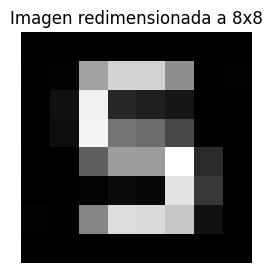

In [27]:
from PIL import Image
import matplotlib.pyplot as plt

# Asegurar la carga de la imagen desde el archivo local
img = Image.open("mi_numero.png").convert("L")

# redimensionar a 8x8
img_resized = img.resize((8, 8), Image.Resampling.LANCZOS)

# mostrar imagen
plt.figure(figsize=(3, 3))
plt.imshow(img_resized, cmap="gray")
plt.title("Imagen redimensionada a 8x8")
plt.axis("off")
plt.show()

# opcional, guardamos la imagen si es necesario
img_resized.save("imagen_8x8.png")

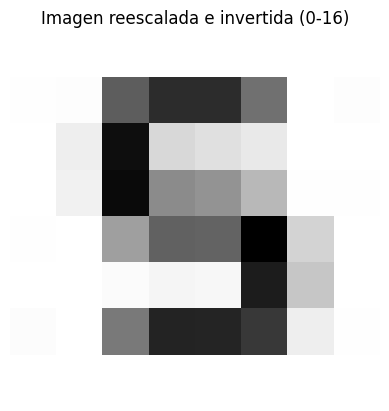

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# reescalar de 0-255 a 0-16 e invertir (fondo negro = 0)
img_array = np.array(img_resized).astype("float32")
img_array = 16 - (img_array / 255 * 16)

# mostrar imagen
plt.imshow(img_array, cmap="gray")
plt.title("Imagen reescalada e invertida (0-16)")
plt.axis("off")
plt.show()


In [25]:
from sklearn.preprocessing import StandardScaler

# normalizar
scaler = StandardScaler()
img_flat = img_array
img_scaled = scaler.fit_transform(img_flat)

# Dar forma (1,8,8) que es el input del modelo
img_tensor = img_scaled.reshape(1, 8, 8)

In [28]:
import numpy as np

# Asegurar que el tensor tenga el formato correcto para la CNN (1, 8, 8, 1)
if len(img_tensor.shape) == 3:
    img_tensor_cnn = np.expand_dims(img_tensor, axis=-1)
else:
    img_tensor_cnn = img_tensor

# Realizar la predicción con el tensor formateado
pred = model.predict(img_tensor_cnn)
digit = np.argmax(pred)
print("Predicción:", digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
Predicción: 3


Finalmente se mostro la imágen para comprobar visualmente si las predicciones de la red neuronal coiciden con los números reales.